
**Análisis exploratorio del catálogo de Netflix.**

Dataset: "Netflix Movies and TV Shows" (Kaggle), archivo netflix_titles.csv.

**Librerías: pandas, matplotlib, seaborn.**





**Celda 1: librerías y carpeta de figuras**

In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("figuras", exist_ok=True)

Eso importa las herramientas y crea la carpeta donde se guardarán las gráficas.

**Celda 2: cargar el CSV**

In [10]:
RUTA_DATOS = "netflix_titles.csv"

df = pd.read_csv(RUTA_DATOS)
print("Filas y columnas:", df.shape)
print("Columnas:", df.columns.tolist())

Filas y columnas: (8807, 12)
Columnas: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


Lee el archivo y muestra cuántas filas y columnas tiene.

**Celda 3: limpieza**

In [11]:
print("Valores nulos por columna:")
print(df.isna().sum())

df["country"] = df["country"].fillna("Desconocido")
df["director"] = df["director"].fillna("Sin dato")
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), errors="coerce")
df["year_added"] = df["date_added"].dt.year

Valores nulos por columna:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


Cuenta los datos faltantes, rellena los vacíos y convierte la fecha de texto en fecha real.

**Celda 4: conteos**

In [12]:
print(df["type"].value_counts())

por_anio = df.groupby("release_year").size()
print(por_anio.tail(20))

paises = (
    df["country"]
    .str.split(", ")
    .explode()
    .value_counts()
    .drop("Desconocido", errors="ignore")
    .head(10)
)
print(paises)

type
Movie      6131
TV Show    2676
Name: count, dtype: int64
release_year
2002      51
2003      61
2004      64
2005      80
2006      96
2007      88
2008     136
2009     152
2010     194
2011     185
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
dtype: int64
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


Cuenta películas y series, títulos por año y los 10 países con más títulos.

**Celda 5: gráfica de películas vs. series**

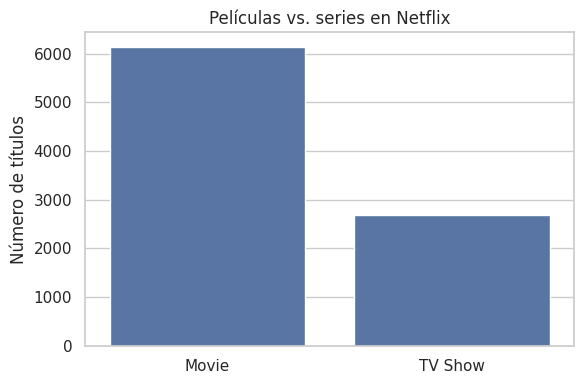

In [13]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="type", ax=ax)
ax.set_title("Películas vs. series en Netflix")
ax.set_xlabel("")
ax.set_ylabel("Número de títulos")
plt.tight_layout()
plt.savefig("figuras/tipo_titulo.png", dpi=150)
plt.show()

**Celda 6: gráfica de los top 10 países**

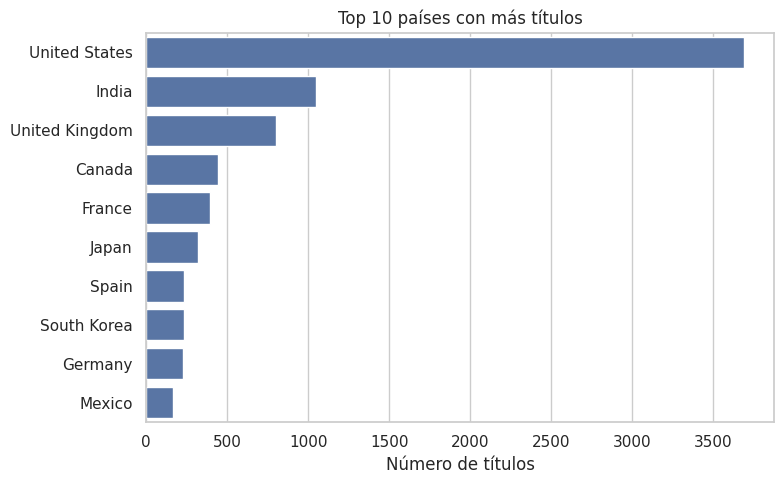

In [14]:
top = paises.reset_index()
top.columns = ["pais", "titulos"]

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=top, x="titulos", y="pais", ax=ax)
ax.set_title("Top 10 países con más títulos")
ax.set_xlabel("Número de títulos")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("figuras/top_paises.png", dpi=150)
plt.show()

**Celda 7: gráfica de estrenos por año**

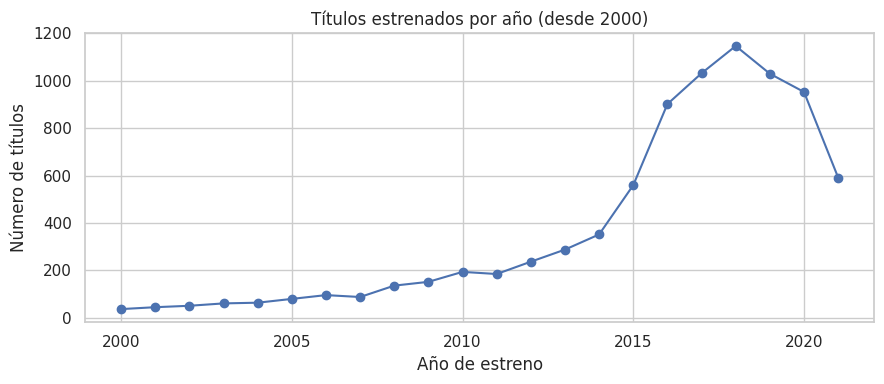

In [15]:
serie = por_anio[por_anio.index >= 2000]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(serie.index, serie.values, marker="o")
ax.set_title("Títulos estrenados por año (desde 2000)")
ax.set_xlabel("Año de estreno")
ax.set_ylabel("Número de títulos")
plt.tight_layout()
plt.savefig("figuras/estrenos_por_anio.png", dpi=150)
plt.show()

**Nota Importante:**
El archivo que se sube se borra si la sesión se reinicia. Si eso pasa, se vuelve a subir antes de ejecutar la celda 2.